# Описание датасета Iris Flower

**Предметная область:** Ботаника, классификация растений. Исследование морфологических различий между видами ирисов.

**Источник:** [Iris Flower Dataset](https://www.kaggle.com/datasets/arshid/iris-flower-dataset) (Kaggle, оригинал — UCI Machine Learning Repository).

**Тип данных:** Реальные данные. 150 образцов ирисов, собранных Эдгаром Андерсоном в Гаспе.

**Набор применим для:**
- **Классификация:** определение вида ириса по измерениям его частей.
- **Кластеризация:** разбиение цветков на группы по морфологическим признакам.
- **Регрессия:** прогнозирование размера лепестка на основе других измерений.

**Признаки:**

| Признак | Тип | Описание |
| :--- | :--- | :--- |
| sepal_length | Числовой | Длина чашелистика, см |
| sepal_width | Числовой | Ширина чашелистика, см |
| petal_length | Числовой | Длина лепестка, см |
| petal_width | Числовой | Ширина лепестка, см |
| species | Категориальный | Вид ириса: Setosa, Versicolor, Virginica |

Для датасета Iris были добавлены два новых признака:
- `petal_area` = petal_length × petal_width — площадь лепестка.
- `sepal_area` = sepal_length × sepal_width — площадь чашелистика.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score


In [29]:
df = pd.read_csv('datasets/IRIS.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [30]:
df.info()
df.describe()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


(150, 5)

In [31]:
df['species'].value_counts()


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [32]:
df['petal_area'] = df['petal_length'] * df['petal_width']
df['sepal_area'] = df['sepal_length'] * df['sepal_width']

**Создаются два новых признака: площадь лепестка и площадь чашелистика.**



In [33]:
print("Дубликатов:", df.duplicated().sum())

Дубликатов: 3


In [34]:
df = df.drop_duplicates()

In [35]:
print("Дубликатов после:", df.duplicated().sum())
print("Размер:", df.shape)

Дубликатов после: 0
Размер: (147, 7)


In [36]:
# Обработка выбросов методом IQR
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 
                'petal_area', 'sepal_area']

Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[~((df[numeric_cols] < (Q1 - 1.5 * IQR)) | 
                (df[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Размер до очистки:", df.shape)
print("Размер после очистки:", df_clean.shape)
print("Удалено строк:", df.shape[0] - df_clean.shape[0])

Размер до очистки: (147, 7)
Размер после очистки: (141, 7)
Удалено строк: 6


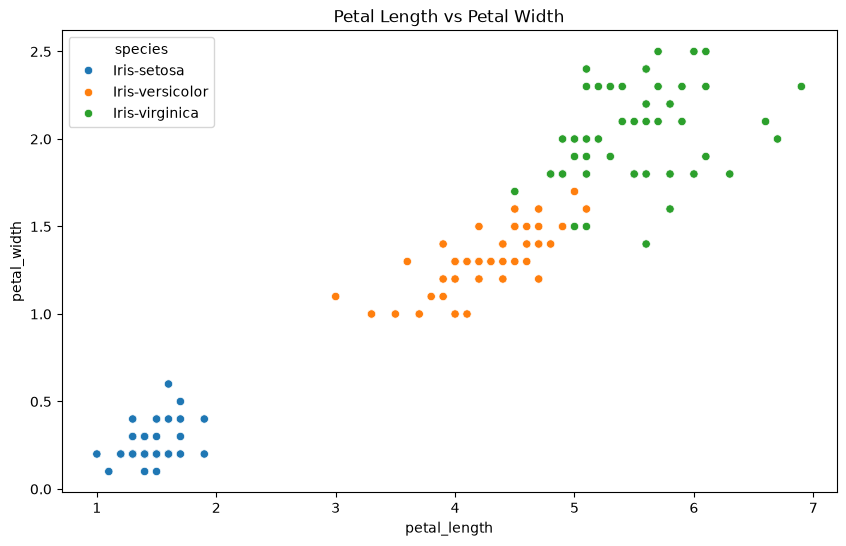

In [45]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='petal_length', y='petal_width', hue='species')
plt.title('Petal Length vs Petal Width')
plt.show()

* Визуализация до KMeans — видно 3 группы по видам.
* Setosa отделена, Versicolor и Virginica пересекаются.

**Дополнительные графики**

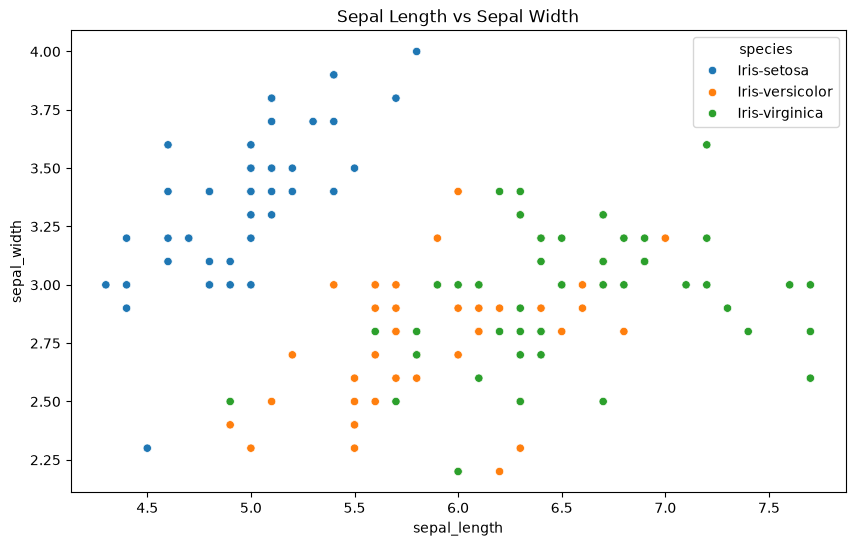

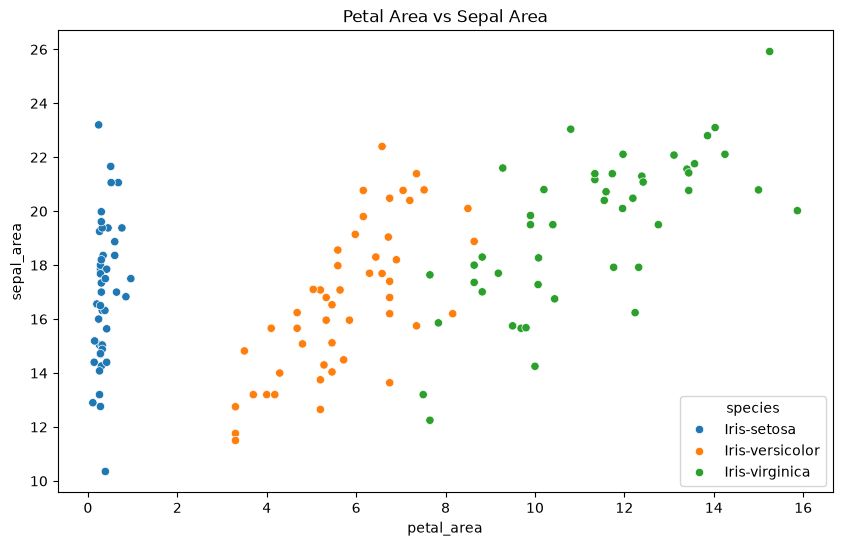

In [56]:
# График 2: sepal_length vs sepal_width
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='sepal_length', y='sepal_width', hue='species')
plt.title('Sepal Length vs Sepal Width')
plt.show()

# График 3: petal_area vs sepal_area
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='petal_area', y='sepal_area', hue='species')
plt.title('Petal Area vs Sepal Area')
plt.show()

**Описание групп на scatter plot:**

На графике Petal Length vs Petal Width видны 3 группы:
- **Setosa** (маленькие лепестки) — отделена от двух других.
- **Versicolor** (средние лепестки) — частично пересекается с Virginica.
- **Virginica** (большие лепестки) — частично пересекается с Versicolor.

На графике Sepal Length vs Sepal Width группы менее выражены — 
признаки хуже разделяют виды.

**Вывод:** наиболее информативные признаки для кластеризации — 
petal_length и petal_width.

In [46]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 
            'petal_area', 'sepal_area']
X = df_clean[features]

KMeans чувствителен к масштабу. Если признаки в разных диапазонах, алгоритм будет отдавать приоритет большим значениям.

In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows wi

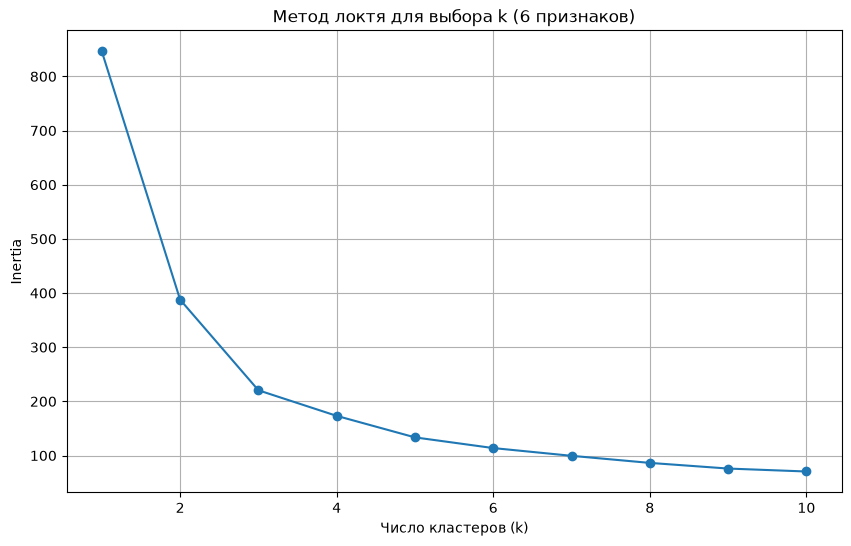

In [48]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Inertia')
plt.title('Метод локтя для выбора k (6 признаков)')
plt.grid(True)
plt.show()

In [49]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['cluster'] = kmeans.fit_predict(X_scaled)

D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


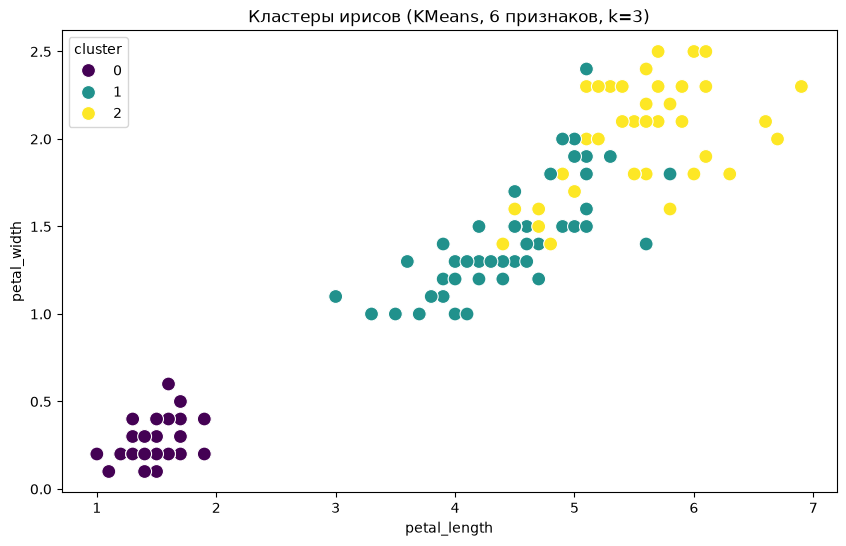

In [50]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='petal_length', y='petal_width', 
                hue='cluster', palette='viridis', s=100)
plt.title('Кластеры ирисов (KMeans, 6 признаков, k=3)')
plt.show()

In [51]:
pd.crosstab(df_clean['species'], df_clean['cluster'])

cluster,0,1,2
species,,,
Iris-setosa,45,0,0
Iris-versicolor,0,38,11
Iris-virginica,0,15,32


In [52]:
df_clean.groupby('cluster')[features].mean()

,sepal_length,sepal_width,petal_length,petal_width,petal_area,sepal_area
cluster,,,,,,
0,4.980000,3.377778,1.462222,0.251111,0.373556,16.901333
1,5.845283,2.683019,4.416981,1.428302,6.444340,15.700377
2,6.744186,3.086047,5.460465,1.972093,10.896512,20.778605


Кластер 0 — маленькие лепестки (Setosa).

Кластер 1 — средние лепестки (Versicolor).

Кластер 2 — большие лепестки (Virginica).

In [53]:
from sklearn.metrics import silhouette_score
score = silhouette_score(X_scaled, df_clean['cluster'])
print(f"Silhouette Score: {score:.3f}")

Silhouette Score: 0.470


**Кластеры не идеально разделены (Versicolor и Virginica пересекаются).**

In [54]:
features_4 = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X_4 = StandardScaler().fit_transform(df_clean[features_4])
kmeans_4 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_4)
score_4 = silhouette_score(X_4, kmeans_4.labels_)
print(f"Silhouette (4 признака): {score_4:.3f}")

Silhouette (4 признака): 0.457


D:\anaconda3\envs\first\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


**Добавление площадей незначительно улучшило кластеризацию (+0.0013).**

**Результаты кластеризации:**

1. KMeans с k=3 разделил 147 ирисов на 3 кластера.
2. Кросс-таблица показала:
   - Setosa - кластер 0 (45 из 45 - 100%).
   - Versicolor - кластер 1 (38 из 49 - 78%).
   - Virginica - кластер 2 (32 из 47 - 68%).
3. Средние по кластерам подтверждают:
   - Кластер 0 - маленькие лепестки (Setosa).
   - Кластер 1 - средние лепестки (Versicolor).
   - Кластер 2 - большие лепестки (Virginica).
4. Silhouette Score:
   - 6 признаков: 0.470.
   - 4 признака: 0.457.
5. Вывод: добавление площадей и удаление выбросов 
   незначительно улучшили качество кластеризации.